# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [1]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
from google.colab import files

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [4]:
import os

csv_path = "/content/Lab_11_QnA_Dataset_Download.csv"
if not os.path.exists(csv_path):
    uploaded = files.upload()
    csv_path = next(name for name in uploaded if name.endswith(".csv"))

df = pd.read_csv(csv_path)
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())


Saving Lab_11_QnA_Dataset.csv to Lab_11_QnA_Dataset (1).csv
Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [5]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [6]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16, padding_idx=0)
        self.rnn = nn.RNN(16, 32, batch_first=True)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        hidden, _ = self.rnn(self.emb(x))
        scores = self.att(hidden).masked_fill(x.unsqueeze(-1) == 0, -1e9)
        weights = torch.softmax(scores, dim=1)
        context = (hidden * weights).sum(dim=1)
        return self.fc(context), weights.squeeze(-1)

model = RNN()


## Step 5 — Train the model
The model learns which answer belongs to each question.

In [7]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    optimizer.zero_grad()
    loss = nn.functional.cross_entropy(model(X)[0], y)
    loss.backward()
    optimizer.step()

print("Training finished!")


Training finished!


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

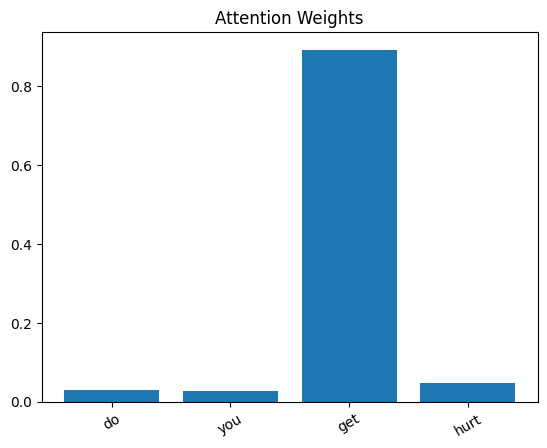

In [8]:
question = df["question"].iloc[0]
words = [tokenizer.index_word[int(i)] for i in X[0] if i != 0]

model.eval()
with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.xticks(rotation=30)
plt.show()


## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

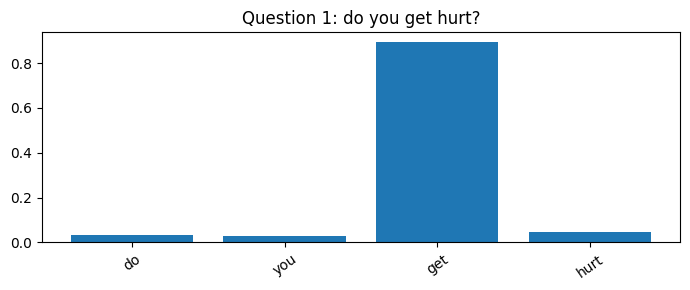

Highest attention word: 'get'
A high weight indicates what the model focused on, not necessarily the most meaningful word.



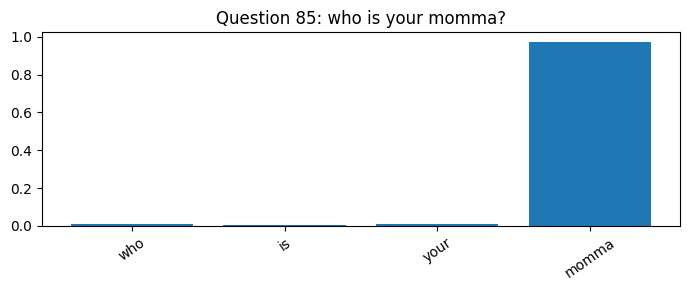

Highest attention word: 'momma'
A high weight indicates what the model focused on, not necessarily the most meaningful word.



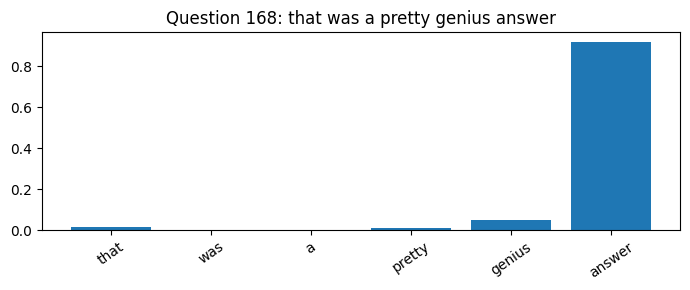

Highest attention word: 'answer'
A high weight indicates what the model focused on, not necessarily the most meaningful word.



In [9]:
# Task 1: Attention weights for three questions
model.eval()
indices = [0, len(df) // 2, len(df) - 1]

for idx in indices:
    words = [tokenizer.index_word[int(i)] for i in X[idx] if i != 0]
    with torch.no_grad():
        _, attention = model(X[idx:idx + 1])

    scores = attention[0, :len(words)].tolist()
    top_word = words[scores.index(max(scores))]

    plt.figure(figsize=(7, 3))
    plt.bar(words, scores)
    plt.title(f"Question {idx + 1}: {df['question'].iloc[idx]}")
    plt.xticks(rotation=35)
    plt.tight_layout()
    plt.show()
    print(f"Highest attention word: '{top_word}'")
    print("A high weight indicates what the model focused on, not necessarily the most meaningful word.\n")


**Task 1 — Answer:** The highlighted word is the word that received the highest attention weight in each chart. These words may help the model recognize the question's meaning, but a high attention weight does not always mean that a word is the most important one to a person. The exact words depend on the trained model.


Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

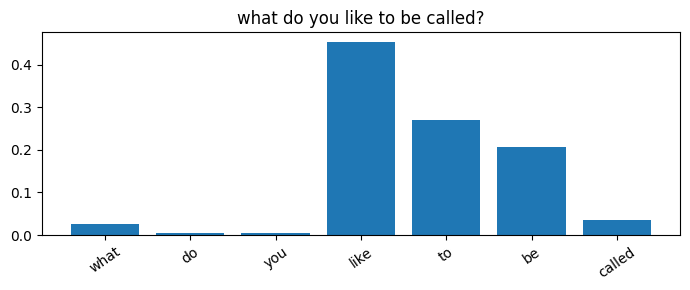

Highest attention word: 'like'



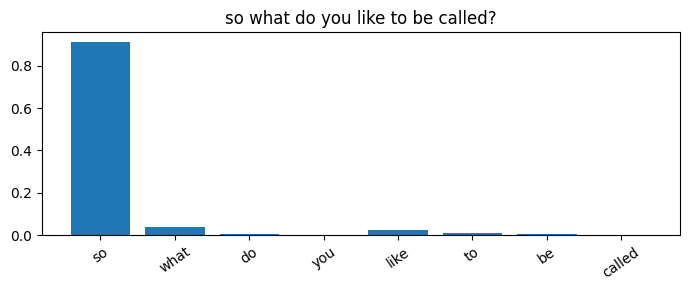

Highest attention word: 'so'

Observation: The model focuses on different words despite the similar questions.
Attention assigns a weight to each word based on the question context.


In [10]:
# Task 2: Find similarly worded questions with the same answer
from difflib import SequenceMatcher
from itertools import combinations

pairs = [(i, j) for _, group in df.groupby("answer_id")
         for i, j in combinations(group.index, 2)
         if df.loc[i, "question"] != df.loc[j, "question"]]

i, j = max(pairs, key=lambda p: SequenceMatcher(
    None, df.loc[p[0], "question"], df.loc[p[1], "question"]).ratio())

model.eval()
top_words = []
for idx in [i, j]:
    words = [tokenizer.index_word[int(t)] for t in X[idx] if t != 0]
    with torch.no_grad():
        _, attention = model(X[idx:idx + 1])
    scores = attention[0, :len(words)].tolist()
    top_word = words[scores.index(max(scores))]
    top_words.append(top_word)

    plt.figure(figsize=(7, 3))
    plt.bar(words, scores)
    plt.title(df.loc[idx, "question"])
    plt.xticks(rotation=35)
    plt.tight_layout()
    plt.show()
    print(f"Highest attention word: '{top_word}'\n")

if top_words[0] == top_words[1]:
    print("Observation: The model focuses most on the same word in both questions.")
else:
    print("Observation: The model focuses on different words despite the similar questions.")
print("Attention assigns a weight to each word based on the question context.")


**Task 2 — Answer:** Questions with similar meanings can give attention to the same important words or to different words because of their wording. The charts show which words the model emphasizes in each sentence. This suggests that attention weights can change with the input context.
